In [ ]:
print('Rida')
    # # 6. Optional Feature Importance breakdown in the application sidebar
    # if hasattr(model, 'feature_importances_'):
    #     st.sidebar.subheader("📈 Water Feature Impact")
    #     st.sidebar.write("Relative feature importance determined by the Random Forest model tree layers:")
        
    #     importance_df = pd.DataFrame({
    #         'Water Attribute': FEATURE_NAMES,
    #         'Importance Score': model.feature_importances_
    #     }).sort_values(by='Importance Score', ascending=False)
        
    #     st.sidebar.bar_chart(data=importance_df, x='Water Attribute', y='Importance Score')


Rida


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.ensemble import RandomForestRegressor

In [6]:
df = pd.read_csv('water_potability.csv')
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ph               2785 non-null   float64
 1   Hardness         3276 non-null   float64
 2   Solids           3276 non-null   float64
 3   Chloramines      3276 non-null   float64
 4   Sulfate          2495 non-null   float64
 5   Conductivity     3276 non-null   float64
 6   Organic_carbon   3276 non-null   float64
 7   Trihalomethanes  3114 non-null   float64
 8   Turbidity        3276 non-null   float64
 9   Potability       3276 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 256.1 KB


In [8]:
print('Null Values in Each Column')
df.isna().sum()

Null Values in Each Column


ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [9]:
print('Sum of Null Values:', df.isna().sum().sum())

Sum of Null Values: 1434


In [29]:
df = df.fillna(df.mean(), inplace = True)
print('Sum of Null values:', df.isna().sum().sum())

Sum of Null values: 0


In [30]:
df.head()

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.080795,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,333.775777,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.775777,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0


How to Overcome missing Values
Task-1: Visualize the distribution of different columns having null values and then decide how to fill them.

In [ ]:
#Data Cleaning
#Imputation

In [ ]:
#Feature Engineering
#Dimensionality Reduction to see which features are important, which we can use and reduce.

In [32]:
col_list = list(df.columns)[0:-1]
col_list


['ph',
 'Hardness',
 'Solids',
 'Chloramines',
 'Sulfate',
 'Conductivity',
 'Organic_carbon',
 'Trihalomethanes',
 'Turbidity']

In [33]:
x = df[col_list]
y = df['Potability']

In [45]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train , y_test = train_test_split(x,y, test_size = 0.2,random_state= 42)

print('Training input shape:', X_train.shape)
print('Training target shape:', y_train.shape)
print('Testing input shape:', X_test.shape)
print('Testing target shape:', y_test.shape)

Training input shape: (2620, 9)
Training target shape: (2620,)
Testing input shape: (656, 9)
Testing target shape: (656,)


In [46]:
df_water = df
df_water['Potability'].value_counts()


Potability
0    1998
1    1278
Name: count, dtype: int64

In [39]:
from sklearn.tree import DecisionTreeClassifier
dt_model = DecisionTreeClassifier()
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_accuracy = accuracy_score(y_test, dt_pred)
print(f'Accuracy of Decision Tree: {round(dt_accuracy * 100, 2)}%')

Accuracy of Decision Tree: 57.47%


In [58]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier()
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_accuracy = accuracy_score(y_test, rf_pred)
print(f'Accuracy of Random Forest: {round(rf_accuracy * 100, 2)}%')

Accuracy of Random Forest: 68.14%


<Axes: >

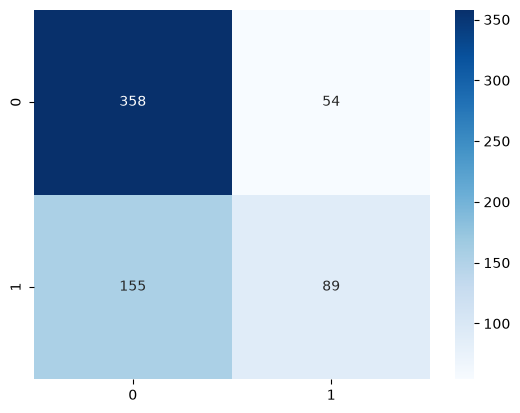

In [59]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
sns.heatmap(confusion_matrix(y_test, rf_pred), annot = True,fmt='d',cmap='Blues')

In [60]:
import joblib
model_filename = "rf_model.pkl"
joblib.dump(rf_model, model_filename)
print(f"Model successfully saved to {model_filename}")


Model successfully saved to rf_model.pkl
